# Combining windows: the sufficient-statistic addition

The six sufficient statistics are indexed by **velocity**, not by Fourier mode, so
windows on different wavelength ranges (even different `dv`/`R`/instrument) combine
by simple **addition** (`combine_stats`) into one joint fit with **shared
`(v1, v2, a1, a2)`**. This notebook makes that concrete: a window blind to the
secondary cannot be fit on its own, but its pure *primary* information **adds** to
the blend window and sharpens the joint velocity estimate.

**Boundary (read `§4`):** this is valid only *within a single epoch* — all pooled
windows must share one true `(v1, v2)`. See [`todcor_method.md`](../../packages/todcor/docs/todcor_method.md) §7.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

# The TODCOR engine, its forward model, and the shared grid/FFT/broadening
# primitives (re-exported from unicor.dsp) all live in one namespace.
import todcor as tf

# Figure style for the SPARTA examples (LaTeX rendering off for portability).
PAPER_STYLE = {
    "font.family": "sans-serif",
    "font.sans-serif": ["Helvetica", "Arial", "DejaVu Sans"],
    "font.size": 11.0, "axes.titlesize": 11.0, "axes.labelsize": 11.0,
    "xtick.labelsize": 10.0, "ytick.labelsize": 10.0, "legend.fontsize": 8.0,
    "axes.linewidth": 0.8,
    "xtick.major.width": 0.7, "ytick.major.width": 0.7,
    "xtick.direction": "in", "ytick.direction": "in",
    "lines.linewidth": 1.2,
    "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight",
    "axes.grid": False,
}
plt.rcParams.update(PAPER_STYLE)

C = tf.C_KMS
def gauss_line(wave, center, depth, fwhm_kms, emission=False):
    sigma = (fwhm_kms / 2.3548) * center / C
    prof = depth * np.exp(-0.5 * ((wave - center) / sigma) ** 2)
    return 1.0 + prof if emission else 1.0 - prof

lam_lo, lam_hi, dv = 4600.0, 4720.0, 3.0
wave, u = tf.log_lambda_grid(lam_lo, lam_hi, dv)
# Primary: an isolated line at 4634 PLUS a shallow line in the 4686 blend.
tmpl1 = (wave, gauss_line(wave, 4634., 0.25, 120.) * gauss_line(wave, 4686., 0.15, 120.))
# Secondary: a broad emitter only at 4686.
tmpl2 = (wave, gauss_line(wave, 4686., 0.60, 400., emission=True))

R = 8000.0
v1t, v2t, a1t, a2t = 80.0, -160.0, 0.70, 0.55
sigma = 0.01
comp = tf.broaden_gaussian_residual(
    tf.composite_flux(wave, [tmpl1, tmpl2], [v1t, v2t], [a1t, a2t]) - 1.0, dv, C / R) + 1.0
rng = np.random.default_rng(0)
data = comp + rng.normal(0, sigma, len(comp))
print(f"injected: v1={v1t:+.0f}  v2={v2t:+.0f}  a1={a1t}  a2={a2t}")

injected: v1=+80  v2=-160  a1=0.7  a2=0.55


## 1. Two windows on one shared velocity grid

Both windows are fit on the **same** `v1_grid`/`v2_grid` (a hard requirement of
`combine_stats`), but cover different wavelength ranges:

- **Window A** — the isolated primary line at 4634 Å (little secondary flux).
- **Window B** — the 4686 Å blend (both components).

`S11`/`S22` (the primary/secondary template powers) tell us which component each
window can constrain:

In [2]:
v1g = np.arange(-300, 301, 3.0)     # SHARED velocity grids
v2g = np.arange(-400, 401, 3.0)

def build_window(lo, hi):
    "Slice a wavelength sub-range and prepare (data_g, g1, g2) for it."
    m = (wave > lo) & (wave < hi)
    ww, tap = wave[m], tf.tukey_window(int(m.sum()))
    dg = (data[m] - 1.0) * tap
    g1 = tf.broaden_gaussian_residual(tf.resample(tmpl1[0], tmpl1[1], ww) - 1.0, dv, C / R) * tap
    g2 = tf.broaden_gaussian_residual(tf.resample(tmpl2[0], tmpl2[1], ww) - 1.0, dv, C / R) * tap
    return dg, g1, g2

winA = build_window(4610, 4660)     # primary-only line
winB = build_window(4665, 4715)     # the blend
stA = tf.window_stats(*winA, dv, v1g, v2g, sigma=sigma)
stB = tf.window_stats(*winB, dv, v1g, v2g, sigma=sigma)
print(f"window A (4634): S11={stA['S11']:8.2f}  S22={stA['S22']:8.2f}  ->  primary only")
print(f"window B (4686): S11={stB['S11']:8.2f}  S22={stB['S22']:8.2f}  ->  both components")

window A (4634): S11=16911.47  S22=    0.00  ->  primary only
window B (4686): S11= 6083.51  S22=291628.41  ->  both components


## 2. Fit the blend window (B) alone

Window B sees both components, so on its own it already estimates `v1` and `v2` —
but the two are **correlated** and `v1` is loose (the primary is shallow inside the
blend). Window A, by contrast, has **zero** secondary power (`S22 ≈ 0`): it cannot
constrain `v2` at all, so a two-component fit to A *alone* is ill-posed (its CRLB is
singular — `nan`). A's value is not as a standalone fit; it is the pure primary
information we will **add** in §3.

window B alone : v1 sigma=1.32  v2 sigma=0.93  rho=-0.22
window A alone : CRLB singular (sigma_v1=nan) -- no secondary information


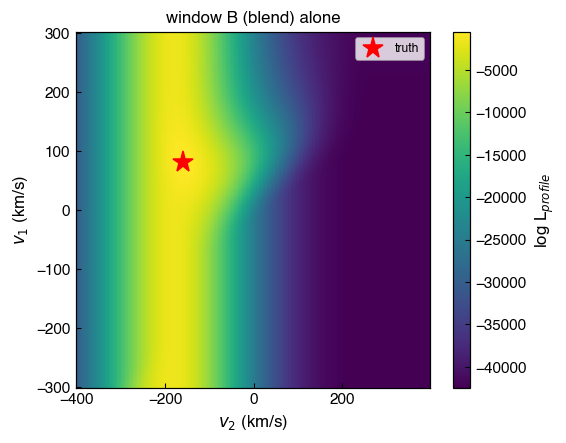

In [3]:
resB = tf.profile_from_stats(stB, v1g, v2g, nonneg=True)
crB = tf.crlb_from_map(resB["logL_profile"], v1g, v2g)
with np.errstate(all="ignore"):     # A has S22~0: a two-component fit is ill-posed
    crA = tf.crlb_from_map(
        tf.profile_from_stats(stA, v1g, v2g, nonneg=True)["logL_profile"], v1g, v2g)
print(f"window B alone : v1 sigma={crB['sigma_v1']:.2f}  v2 sigma={crB['sigma_v2']:.2f}  rho={crB['rho']:+.2f}")
print(f"window A alone : CRLB singular (sigma_v1={crA['sigma_v1']}) -- no secondary information")

fig, ax = plt.subplots(figsize=(5.2, 4.2))
im = ax.pcolormesh(v2g, v1g, resB["logL_profile"], shading="auto", cmap="viridis")
ax.plot(v2t, v1t, "r*", ms=14, label="truth")
ax.set_xlabel("$v_2$ (km/s)"); ax.set_ylabel("$v_1$ (km/s)")
ax.set_title("window B (blend) alone"); ax.legend(fontsize=8)
fig.colorbar(im, ax=ax, label="log L$_{profile}$")

## 3. Add window A's primary information

`combine_stats([stA, stB])` sums the six statistics element-wise — because each
window's χ² is linear in them, the sum **is** the joint χ² with one shared
`(v1, v2, a1, a2)`. Adding A's pure primary constraint tightens `v1` and
de-correlates the pair. The CRLB 1σ ellipses make it visible — drawn **at the
truth** so we compare their *size and tilt*, not their centring (the velocity grid
step here, 3 km/s, is coarser than σ, so each grid peak is quantised to ±½ step
and would offset the ellipses artificially):

combined fit : v1=+81.0  v2=-160.0  a1=0.70  a2=0.55
truth        : v1=+80.0  v2=-160.0  a1=0.70  a2=0.55
v1 sigma : B alone 1.32  ->  A+B 0.70 km/s
corr rho : B alone -0.22  ->  A+B -0.08


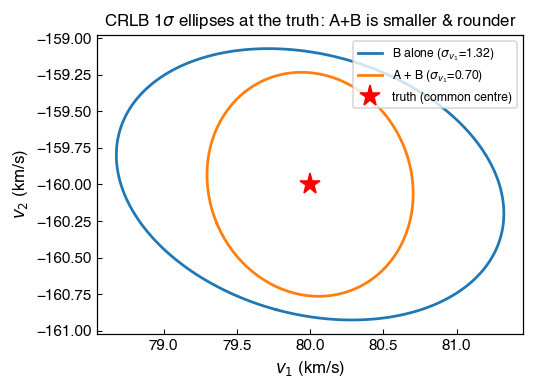

In [4]:
stAB = tf.combine_stats([stA, stB])
resAB = tf.profile_from_stats(stAB, v1g, v2g, nonneg=True)
crAB = tf.crlb_from_map(resAB["logL_profile"], v1g, v2g)
bb = resAB["best"]
print(f"combined fit : v1={bb['v1']:+.1f}  v2={bb['v2']:+.1f}  a1={bb['a1']:.2f}  a2={bb['a2']:.2f}")
print(f"truth        : v1={v1t:+.1f}  v2={v2t:+.1f}  a1={a1t:.2f}  a2={a2t:.2f}")
print(f"v1 sigma : B alone {crB['sigma_v1']:.2f}  ->  A+B {crAB['sigma_v1']:.2f} km/s")
print(f"corr rho : B alone {crB['rho']:+.2f}  ->  A+B {crAB['rho']:+.2f}")

th = np.linspace(0, 2*np.pi, 200)
def ellipse(cr):
    "1-sigma error ellipse, drawn at the truth to compare shape (not centring)."
    val, vec = np.linalg.eigh(cr["cov"])
    e = vec @ (np.sqrt(val)[:, None] * np.vstack([np.cos(th), np.sin(th)]))
    return v1t + e[0], v2t + e[1]

fig, ax = plt.subplots(figsize=(5.0, 4.4))
xB, yB = ellipse(crB); xA, yA = ellipse(crAB)
ax.plot(xB, yB, "C0", lw=1.8, label=f"B alone ($\\sigma_{{v_1}}$={crB['sigma_v1']:.2f})")
ax.plot(xA, yA, "C1", lw=1.8, label=f"A + B ($\\sigma_{{v_1}}$={crAB['sigma_v1']:.2f})")
ax.plot(v1t, v2t, "r*", ms=14, label="truth (common centre)")
ax.set_xlabel("$v_1$ (km/s)"); ax.set_ylabel("$v_2$ (km/s)")
ax.set_title("CRLB 1$\\sigma$ ellipses at the truth: A+B is smaller & rounder")
ax.legend(fontsize=8, loc="upper right"); ax.set_aspect("equal")

## 4. The boundary — what you may and may not add

`combine_stats` is powerful but has two constraints it does **not** check for you,
plus one modelling caveat:

1. **Same velocity grid.** The `b1`/`b2`/`A12` arrays are summed element-wise, so
   every pooled window must be evaluated on the *identical* `v1_grid`/`v2_grid`
   (the `dv`/`R`/instrument may still differ).
2. **Same epoch — never across epochs.** All pooled windows must share one true
   `(v1, v2)`. Different epochs have different velocities (orbital motion), so a
   shared-`v` fit across epochs is meaningless. To build an orbit you fit **each
   epoch** separately (pooling that epoch's lines), then feed the per-epoch
   velocities to the orbit fit.
3. **Shared amplitudes are an approximation.** One global `(a1, a2)` is shared
   across all pooled lines. For chemically-distinct lines (an absorption primary
   vs an emission secondary) the light/line-strength ratio is line-dependent, so a
   single amplitude pair is a modelling simplification, not an exact truth.

## Summary

Pooling windows is just **adding their sufficient statistics** — a window blind to
one component (`S22 ≈ 0`) contributes nothing to that velocity, but combined with a
window that sees it, the joint fit pins both velocities. Do it **within one epoch,
on a shared velocity grid**; never across epochs.

This closes the TODCOR tutorial set: `01_method` (the derivation), `02` (a single
applied fit + CRLB), and `03` (combination). The canonical written spec is
[`todcor_method.md`](../../packages/todcor/docs/todcor_method.md); the real-data application it was extracted from (WR 2) lives in the
parent research repository.